# QSVT in PennyLane: a guided tour of `qsvtlab`

The **quantum singular value transformation** (QSVT) is a single framework that covers most
known quantum algorithms. Given a *block encoding* of a matrix $A$ (a unitary whose top-left
block is $A/\alpha$), a sequence of $d$ calls to it, interleaved with projector-controlled
phases, implements a degree-$d$ polynomial $p(A/\alpha)$.

This notebook walks through three pieces:

1. **Phase finding.** Turn a polynomial into QSVT phases at degrees in the thousands.
2. **A linear-system solver.** Prepare $|x\rangle \propto A^{-1}|b\rangle$ end to end and verify it against `numpy.linalg.solve`.
3. **Hamiltonian simulation.** Implement $e^{-iHt}$ and compare its CNOT cost with Trotterization.

In [1]:
import numpy as np
import pennylane as qml
import matplotlib.pyplot as plt
from numpy.polynomial import chebyshev as C
import qsvtlab as ql
print("PennyLane", qml.__version__)

PennyLane 0.45.1


## 1. From a polynomial to phases

`qml.poly_to_angles` takes the polynomial in the *monomial* basis, which is exponentially
ill-conditioned. `qsvtlab.solve_qsp_phases` works directly in the Chebyshev basis, using
fixed-point iteration with a Newton fallback.

In [2]:
kappa = 20
c, scale = ql.rescale(ql.inverse_poly(kappa, eps=1e-3), 0.5)   # max|p| = 0.5
print("degree:", len(c) - 1)

try:
    qml.poly_to_angles(C.cheb2poly(c), "QSVT")
except Exception as e:
    print("qml.poly_to_angles failed:", type(e).__name__)

%time res = ql.solve_qsp_phases(c)
x = np.linspace(-1, 1, 2001)
print("method:", res.method, "| max error of the QSP response:",
      np.abs(ql.qsp_response(res.phases, x) - C.chebval(x, c)).max())

degree: 515
qml.poly_to_angles failed: AssertionError
CPU times: user 67.6 ms, sys: 206 μs, total: 67.8 ms
Wall time: 67.8 ms
method: fpi | max error of the QSP response: 6.718625655821597e-12


## 2. Block encodings and a sanity check

`qml.BlockEncode` rescales its input by an $\infty$-norm bound whenever that bound exceeds 1.
For a matrix with spectral norm 1 this quietly shrinks the spectrum:

In [3]:
rng = np.random.default_rng(0)
Q, _ = np.linalg.qr(rng.normal(size=(4, 4)))
A = Q @ np.diag([1, -0.5, 0.3, -0.2]) @ Q.T
U = qml.matrix(qml.BlockEncode(A, wires=[0, 1, 2]))
print("max |block - A| with qml.BlockEncode:   ", np.abs(U[:4, :4] - A).max())
be = ql.unitary_dilation(A, system_wires=[1, 2], ancilla_wire=0)
U2 = be.meta["matrix"]
print("max |block - A| with ql.unitary_dilation:", np.abs(U2[:4, :4] - A).max())

max |block - A| with qml.BlockEncode:    0.2261690589318558
max |block - A| with ql.unitary_dilation: 2.220446049250313e-16


Now we check the whole QSVT circuit. That includes the extra ancilla used to keep only the
real part of the polynomial. The post-selected block should equal $p(A)$ to machine precision.

In [4]:
c3 = np.array([0, 0.3, 0, -0.2])            # p(x) = 0.3 T1 - 0.2 T3
block = ql.qsvt_block(be, ql.qsvt_phases_for(c3), lcu_wire="r")
ev, V = np.linalg.eigh(A)
print("max |block - p(A)|:", np.abs(block - V @ np.diag(C.chebval(ev, c3)) @ V.T).max())
print(qml.draw(lambda: ql.real_qsvt(be, ql.qsvt_phases_for(c3), "r"), max_length=110, show_matrices=False)())

max |block - p(A)|: 4.1294745427968195e-13
r: ──H─╭U(M0)────────╭U(M2)─────────╭U(M2)────────╭U(M3)──H─┤  
0: ────├U(M0)─╭U(M1)─├U(M2)─╭U(M1)†─├U(M2)─╭U(M1)─├U(M3)────┤  
1: ────├U(M0)─├U(M1)─├U(M2)─├U(M1)†─├U(M2)─├U(M1)─├U(M3)────┤  
2: ────╰U(M0)─╰U(M1)─╰U(M2)─╰U(M1)†─╰U(M2)─╰U(M1)─╰U(M3)────┤  


## 3. Solving $Ax = b$

`qsvt_solve` prepares $|b\rangle$, runs QSVT with an approximation to $1/x$, and post-selects.
A non-Hermitian $A$ is embedded automatically as $\begin{psmallmatrix}0&A\\A^\dagger&0\end{psmallmatrix}$.
The success probability also gives back $\|A^{-1}b\|$, which normalization would otherwise lose.

In [5]:
A = rng.normal(size=(4, 4))
b = rng.normal(size=4)
r = ql.qsvt_solve(A, b, eps=1e-3)
x = np.linalg.solve(A, b)
print(f"kappa = {r.kappa:.1f}, degree = {r.degree}, qubits = {r.n_qubits}")
print(f"fidelity with numpy solution: {r.fidelity:.12f}")
print(f"success probability: {r.success_prob:.2e}")
print(f"||x|| estimated {r.norm_estimate:.5f} vs exact {np.linalg.norm(x):.5f}")

kappa = 5.8, degree = 131, qubits = 5
fidelity with numpy solution: 0.999999998956
success probability: 2.68e-03
||x|| estimated 0.39043 vs exact 0.39044


The same solver accepts a Pauli-sum operator. It then uses PennyLane's
`PrepSelPrep`, a block encoding that compiles to real gates:

In [6]:
H = qml.dot([1.0, 0.5, 0.4, 0.3], [qml.Z(0) @ qml.Z(1), qml.X(0), qml.X(1), qml.Z(0)])
r = ql.qsvt_solve(H, np.ones(4), eps=1e-4)
print(f"LCU encoding: lambda = {r.alpha}, degree = {r.degree}, fidelity = {r.fidelity:.10f}")

LCU encoding: lambda = 2.1999999999999997, degree = 65, fidelity = 0.9999999999

## 4. Hamiltonian simulation: QSVT vs Trotter

$e^{-iHt} = \cos(Ht) - i\sin(Ht)$. Each term is a Jacobi–Anger polynomial in $H/\lambda$ with
$\tau = \lambda t$. The two QSVT sequences are combined with one extra ancilla.

(Watch out: `qml.TrotterProduct(H, t)` approximates $e^{+iHt}$.)

In [7]:
H = ql.tfim(3)
for eps in [1e-2, 1e-6, 1e-10]:
    s = ql.qsvt_time_evolution(H, t=1.0, eps=eps)
    print(f"eps={eps:.0e}: degrees (cos, sin) = ({s.deg_cos}, {s.deg_sin}), "
          f"error = {s.error:.1e}, CNOTs = {ql.qsvt_cnot_cost(H, s.deg_cos, s.deg_sin)}")
for steps in [4, 32, 256]:
    print(f"Trotter-2, {steps:3d} steps: error = {ql.trotter_error(H, 1.0, steps, 2):.1e}, "
          f"CNOTs = {ql.trotter_cnot_cost(H, steps, 2)}")

eps=1e-02: degrees (cos, sin) = (8, 9), error = 4.9e-04, CNOTs = 1961


eps=1e-06: degrees (cos, sin) = (14, 13), error = 5.5e-08, CNOTs = 2986


eps=1e-10: degrees (cos, sin) = (18, 19), error = 3.3e-12, CNOTs = 4011
Trotter-2,   4 steps: error = 3.3e-02, CNOTs = 32
Trotter-2,  32 steps: error = 5.0e-04, CNOTs = 256


Trotter-2, 256 steps: error = 7.9e-06, CNOTs = 2048


For a small system at loose precision, Trotter is cheaper. A QSVT query (`PrepSelPrep`)
costs far more than a Trotter step. QSVT's error, though, falls *super-exponentially* with
degree, while Trotter's falls only polynomially, so QSVT wins at high precision. See
`figures/hamsim_error_vs_cnots.png` (produced by `benchmarks/run_benchmarks.py`) for where
the curves cross.

## 5. Chemistry: ground states by QSVT eigenstate filtering

QSVT applies the Lin–Tong filter polynomial $R_\ell(x;\delta)$ to $(H-\mu)/\alpha$, starting
from the Hartree–Fock state. The post-selection probability is

$$p(\mu) = s^2\sum_k |\langle E_k|\mathrm{HF}\rangle|^2\, R_\ell\big((E_k-\mu)/\alpha\big)^2 .$$

Sweeping $\mu$ therefore *measures the spectrum*. Each peak sits at an eigenvalue and its
height is the overlap with Hartree–Fock. No prior knowledge of $E_0$ is needed. Below we
use stretched H₂, where Hartree–Fock overlaps the true ground state only 71%.

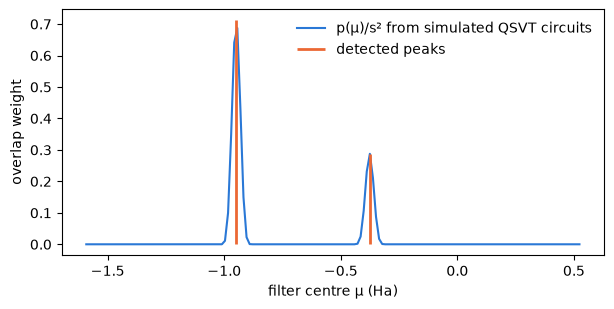

peaks (Ha): [-0.948641 -0.376434]
exact E0  : -0.948641  | circuits run: 177


In [8]:
H, n, hf = ql.molecule_hamiltonian(["H", "H"], [[0, 0, 0], [0, 0, 2.0]])
F = ql.EigenFilter(H, hf)
sp = F.spectroscopy(ell=100, delta=0.03, n_mu=161)
ev = np.linalg.eigvalsh(F.Hmat)

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(sp.mu, sp.p_success / 0.81, color="#2a78d6", label="p(μ)/s² from simulated QSVT circuits")
ax.vlines(sp.peaks, 0, sp.weights, color="#eb6834", lw=2, label="detected peaks")
ax.set_xlabel("filter centre μ (Ha)"); ax.set_ylabel("overlap weight"); ax.legend(frameon=False)
plt.show()
print("peaks (Ha):", np.round(sp.peaks, 6))
print("exact E0  :", round(ev[0], 6), " | circuits run:", sp.n_circuits)

Only two peaks appear, although H₂ has 16 eigenstates. The Hartree–Fock state has
singlet, gerade symmetry and so overlaps only states of that symmetry: the filter is
measuring symmetry selection rules. Next, filter at the lowest peak to prepare the ground
state:

In [9]:
for ell in [50, 100, 200]:
    g = F.prepare_ground_state(sp.peaks[0], ell=ell)
    print(f"degree {2*ell:3d}: |E0 error| = {abs(sp.peaks[0]-g.energy_exact):.1e} Ha, "
          f"fidelity = {g.fidelity:.12f}, success prob = {g.success_prob:.3f} "
          f"(HF overlap {g.hf_overlap:.3f})")

degree 100: |E0 error| = 2.9e-07 Ha, fidelity = 0.998990820664, success prob = 0.577 (HF overlap 0.712)
degree 200: |E0 error| = 2.9e-07 Ha, fidelity = 0.999997590978, success prob = 0.577 (HF overlap 0.712)


degree 400: |E0 error| = 2.9e-07 Ha, fidelity = 0.999999999984, success prob = 0.577 (HF overlap 0.712)


The success probability approaches $s^2|\gamma_0|^2$: the filter keeps the
ground-state component of the Hartree–Fock state and removes everything else. This
algorithm sits underneath fault-tolerant ground-state preparation, and it is what
`figures/chem_h4_spectrum.png` scales up to an 8-qubit H₄ chain.